# Семинар 3. Численное интегрирование (версия преподавателя)

**Курс «Численные методы», 2 курс бакалавриата**

**План семинара**

Разминка: решение уравнений
0. Немного Python
1. Постановка задачи
2. Формулы прямоугольников
3. Формула трапеций
4. Формула Симпсона
5. Формула Рунге–Ромберга
6. Методика Ричардсона
7. Интегрирование в `scipy`
8. Задачи
9. Домашнее задание

> **Для преподавателя.** Ориентировочный тайминг (90 минут):
> - 0–3 мин — вступление, проверка пакетов;
> - 3–9 мин — разминка (самостоятельно, затем показать решение);
> - 9–12 мин — раздел 0 (срезы с шагом, `np.sum`);
> - 12–16 мин — раздел 1 (постановка, иллюстрация);
> - 16–27 мин — раздел 2 (прямоугольники);
> - 27–35 мин — раздел 3 (трапеции);
> - 35–45 мин — раздел 4 (Симпсон, сравнение);
> - 45–48 мин — «когда порядок не достигается»;
> - 48–58 мин — раздел 5 (Рунге–Ромберг);
> - 58–70 мин — раздел 6 (Ричардсон);
> - 70–74 мин — раздел 7 (scipy);
> - 74–87 мин — задачи;
> - 87–90 мин — итоги и домашнее задание.
> 
> **Минимальный путь для слабой группы.** Обязательно: разделы 0–4 без подраздела «Когда порядок не достигается», раздел 5 целиком (включая совпадение с формулой Симпсона), в разделе 6 функция `richardson` и два её запуска (трапеции и Симпсон). Можно пропустить: мини-задачи в разделах 3 и 5, подраздел про эффективный порядок, раздел 7 сократить до одного вызова `quad`. Из задач в классе: 1, 2 и 5 (возвращение к разминке).
> 
> **Сильная группа** успеет всё, включая задачи 6–7.

**Напоминание по работе с блокнотом**

- Ячейка выполняется сочетанием **Shift + Enter**. Ячейки выполняются в том порядке, в котором вы их запускаете.
- Ошибка `NameError: name '...' is not defined` обычно означает, что пропущена одна из ячеек выше.
- Если ячейка выполняется слишком долго, остановите её: кнопка «стоп» слева от ячейки или меню **Runtime → Interrupt execution** в Colab (**Kernel → Interrupt** в Jupyter).
- Ячейки **«Пишем вместе»** заполняем вместе на семинаре. Ячейки с готовым кодом нужно просто запустить.

In [1]:
import importlib.util

for name in ['numpy', 'scipy', 'matplotlib']:
    if importlib.util.find_spec(name) is None:
        print(f'{name}: НЕ установлен, выполните  %pip install {name}')
    else:
        print(f'{name}: OK')

numpy: OK
scipy: OK
matplotlib: OK


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True

## Разминка: решение уравнений

1. С помощью `brentq` найдите корень уравнения $x^3 + x - 1 = 0$ на отрезке $[0, 1]$.
2. Вопрос: как найти $x$, при котором
$$\int_0^x e^{-t^2}\,dt = 0.5\,?$$
Чего не хватает, чтобы применить `brentq`?

In [3]:
def f_warm(x):
    return x**3 + x - 1

print(brentq(f_warm, 0.0, 1.0))

0.682327803828082


> **Для преподавателя.** Разминку студенты делают сами (4–5 минут), затем покажите решение. Ожидаемый результат: `0.682327803828082`.
> 
> Ответ на второй вопрос: не хватает способа вычислить интеграл. Первообразная $e^{-t^2}$ не выражается через элементарные функции, поэтому интеграл нужно считать численно. Этому посвящён семинар; к задаче вернёмся в конце (задача 5). Не раскрывайте решение сейчас.
> 
> Типичные ошибки: забыли, что `brentq` принимает функцию без скобок и концы отрезка; `ValueError` про одинаковые знаки, если отрезок выбран неверно.

## 0. Немного Python

Сегодня понадобятся срезы с шагом `y[начало:конец:шаг]` и функция `np.sum`.

In [4]:
y_demo = np.arange(9)
print(y_demo)
print(y_demo[1:-1])
print(y_demo[1:-1:2])
print(y_demo[2:-1:2])
print(np.sum(y_demo))

[0 1 2 3 4 5 6 7 8]
[1 2 3 4 5 6 7]
[1 3 5 7]
[2 4 6]
36


> **Для преподавателя.** Ожидаемый результат: `[0 1 2 3 4 5 6 7 8]`, `[1 2 3 4 5 6 7]`, `[1 3 5 7]`, `[2 4 6]`, `36`.
> 
> Поясните: `1:-1` — все элементы, кроме первого и последнего; третье число — шаг. `[1:-1:2]` — внутренние элементы с нечётными номерами, `[2:-1:2]` — с чётными. Именно эти срезы понадобятся в формуле Симпсона.

## 1. Постановка задачи

Требуется вычислить

$$I = \int_a^b f(x)\,dx.$$

Отрезок разбивается на $N$ равных частей: $h = \dfrac{b - a}{N}$, узлы $x_i = a + ih$, $i = 0, \dots, N$. Приближённое значение интеграла на такой сетке обозначим $U_N$.

**Порядок точности.** Формула имеет порядок $p$, если

$$I - U_N \approx C h^p.$$

При увеличении $N$ в 2 раза погрешность уменьшается в $2^p$ раз: в 2 раза при $p = 1$, в 4 раза при $p = 2$, в 16 раз при $p = 4$.

**Тестовый интеграл** на этом семинаре:

$$\int_0^{\pi/2} \sin x\,dx = 1.$$

Три способа приблизить площадь под графиком (просто запустите):

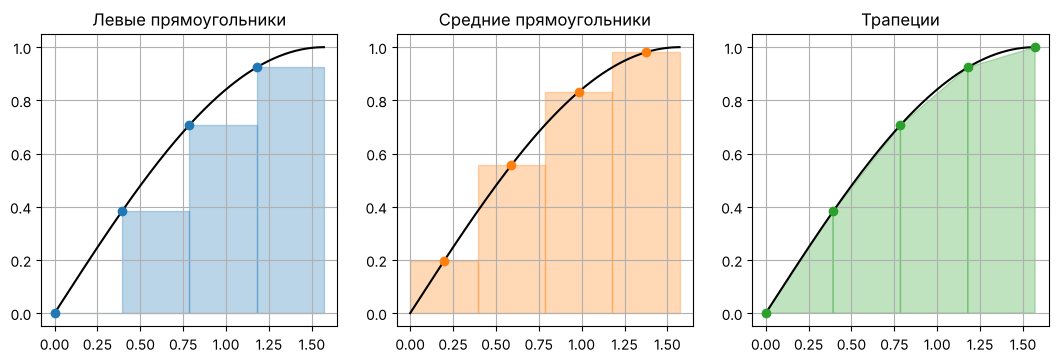

In [5]:
N_ill = 4
a_ill, b_ill = 0.0, np.pi / 2
h_ill = (b_ill - a_ill) / N_ill
x_fine = np.linspace(a_ill, b_ill, 200)
x_nodes = np.linspace(a_ill, b_ill, N_ill + 1)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
titles = ['Левые прямоугольники', 'Средние прямоугольники', 'Трапеции']
for k in range(3):
    ax[k].plot(x_fine, np.sin(x_fine), 'k')
    ax[k].set_title(titles[k])
for i in range(N_ill):
    x_l, x_r = x_nodes[i], x_nodes[i + 1]
    x_m = 0.5 * (x_l + x_r)
    ax[0].fill([x_l, x_l, x_r, x_r], [0, np.sin(x_l), np.sin(x_l), 0], alpha=0.3, color='C0', edgecolor='C0')
    ax[0].plot(x_l, np.sin(x_l), 'o', color='C0')
    ax[1].fill([x_l, x_l, x_r, x_r], [0, np.sin(x_m), np.sin(x_m), 0], alpha=0.3, color='C1', edgecolor='C1')
    ax[1].plot(x_m, np.sin(x_m), 'o', color='C1')
    ax[2].fill([x_l, x_l, x_r, x_r], [0, np.sin(x_l), np.sin(x_r), 0], alpha=0.3, color='C2', edgecolor='C2')
ax[2].plot(x_nodes, np.sin(x_nodes), 'o', color='C2')
plt.show()

Вспомогательная функция: печатает погрешность метода для $N = 4, 8, \dots, 128$ и отношение соседних погрешностей (просто запустите).

In [6]:
def order_table(method, f, a, b, I_exact):
    print('    N    погрешность   отношение')
    err_old = None
    for N in [4, 8, 16, 32, 64, 128]:
        err = abs(I_exact - method(f, a, b, N))
        if err_old is None:
            print(f'{N:5d}   {err:.3e}')
        else:
            print(f'{N:5d}   {err:.3e}    {err_old / err:7.2f}')
        err_old = err

## 2. Формулы прямоугольников

**Левые прямоугольники:** на каждом отрезке функция заменяется её значением в левом конце.

$$U_N = h\sum_{i=0}^{N-1} f(x_i), \qquad p = 1.$$

In [7]:
def rect_left(f, a, b, N):
    h = (b - a) / N
    x = a + h * np.arange(N)
    return h * np.sum(f(x))

In [8]:
U_left_10 = rect_left(np.sin, 0, np.pi / 2, 10)
U_left_20 = rect_left(np.sin, 0, np.pi / 2, 20)
print(U_left_10, U_left_20)
print(1 - U_left_10, 1 - U_left_20)
print((1 - U_left_10) / (1 - U_left_20))

0.9194031700146124 0.9602159970786605
0.08059682998538764 0.039784002921339545
2.0258602470129197


> **Для преподавателя.** Ожидаемый результат: `0.9194 0.9602`, погрешности `0.0806 0.0398`, отношение `2.03`.
> 
> Вопрос аудитории перед третьей строкой: «Во сколько раз должна уменьшиться погрешность, если порядок первый?» Ответ: в 2 раза.
> 
> Типичные ошибки: `np.arange(N + 1)` (лишний узел), `np.linspace(a, b, N)` вместо узлов с шагом h, забыли умножить на h.

In [9]:
order_table(rect_left, np.sin, 0, np.pi / 2, 1.0)

    N    погрешность   отношение
    4   2.092e-01
    8   1.014e-01       2.06
   16   4.989e-02       2.03
   32   2.474e-02       2.02
   64   1.232e-02       2.01
  128   6.148e-03       2.00


> **Для преподавателя.** Ожидаемый результат: отношения около 2 (от 2.06 до 2.00). Порядок первый.

**Средние прямоугольники:** значение берётся в середине каждого отрезка.

$$U_N = h\sum_{i=0}^{N-1} f\!\left(x_i + \frac{h}{2}\right), \qquad p = 2.$$

In [10]:
def rect_mid(f, a, b, N):
    h = (b - a) / N
    x = a + h * (np.arange(N) + 0.5)
    return h * np.sum(f(x))

order_table(rect_mid, np.sin, 0, np.pi / 2, 1.0)

    N    погрешность   отношение
    4   6.455e-03
    8   1.608e-03       4.01
   16   4.017e-04       4.00
   32   1.004e-04       4.00
   64   2.510e-05       4.00
  128   6.275e-06       4.00


> **Для преподавателя.** Ожидаемый результат: отношения около 4. Порядок второй.
> 
> Подчеркните: число вычислений функции то же самое, изменилось только положение точек, а точность выросла на порядки (при N = 128 погрешность $6 \cdot 10^{-6}$ вместо $6 \cdot 10^{-3}$).
> 
> Типичная ошибка: `np.arange(N) + 0.5` без скобок: `a + h * np.arange(N) + 0.5` сдвигает узлы на 0.5, а не на h/2.

**Мини-задача.** Вычислите $\displaystyle\int_1^2 \frac{dx}{x} = \ln 2$ обоими методами при $N = 10$ и найдите погрешности (точное значение `np.log(2)`).

In [11]:
def f_inv(x):
    return 1 / x

print(np.log(2) - rect_left(f_inv, 1, 2, 10))
print(np.log(2) - rect_mid(f_inv, 1, 2, 10))

-0.025624222615482695
0.0003118201499850981


> **Для преподавателя.** Ожидаемый результат: погрешности около `-0.0256` и `0.00031`.

## 3. Формула трапеций

На каждом отрезке функция заменяется прямой, проходящей через значения на концах.

$$U_N = h\left(\frac{f_0}{2} + f_1 + f_2 + \dots + f_{N-1} + \frac{f_N}{2}\right), \qquad p = 2.$$

In [12]:
def trapezoid(f, a, b, N):
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    return h * (y[0] / 2 + np.sum(y[1:-1]) + y[-1] / 2)

order_table(trapezoid, np.sin, 0, np.pi / 2, 1.0)

    N    погрешность   отношение
    4   1.288e-02
    8   3.215e-03       4.01
   16   8.033e-04       4.00
   32   2.008e-04       4.00
   64   5.020e-05       4.00
  128   1.255e-05       4.00


> **Для преподавателя.** Ожидаемый результат: отношения около 4. Порядок второй.
> 
> Типичная ошибка: `np.linspace(a, b, N)` вместо `N + 1` (N отрезков — это N + 1 узел).

Сравним погрешности средних прямоугольников и трапеций при одном и том же $N$.

In [13]:
print(1 - rect_mid(np.sin, 0, np.pi / 2, 10))
print(1 - trapezoid(np.sin, 0, np.pi / 2, 10))

-0.001028824142708551
0.0020570136456428134


> **Для преподавателя.** Ожидаемый результат: `-0.00103` и `0.00206`.
> 
> Вопрос аудитории: что можно заметить? Ответ: погрешности разного знака, и у трапеций она по модулю почти ровно вдвое больше. Значит, комбинация $(2U^{\text{ср}} + U^{\text{тр}})/3$ должна быть намного точнее. К этому вернёмся в следующем разделе.

**Мини-задача.** Вычислите $\displaystyle\int_1^2 \frac{dx}{x}$ по формуле трапеций при $N = 10$ и сравните погрешность с погрешностью средних прямоугольников.

In [14]:
print(np.log(2) - trapezoid(f_inv, 1, 2, 10))
print(np.log(2) - rect_mid(f_inv, 1, 2, 10))

-0.0006242226154826724
0.0003118201499850981


> **Для преподавателя.** Ожидаемый результат: `-0.00062` и `0.00031`: снова разные знаки и отношение около двух.

## 4. Формула Симпсона (парабол)

На каждой паре соседних отрезков функция заменяется параболой, проходящей через три точки. Число отрезков $N$ должно быть **чётным**.

$$U_N = \frac{h}{3}\left(f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 2f_{N-2} + 4f_{N-1} + f_N\right), \qquad p = 4.$$

In [15]:
def simpson(f, a, b, N):
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    return h / 3 * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]) + y[-1])

order_table(simpson, np.sin, 0, np.pi / 2, 1.0)

    N    погрешность   отношение
    4   1.346e-04
    8   8.296e-06      16.22
   16   5.167e-07      16.06
   32   3.227e-08      16.01
   64   2.016e-09      16.00
  128   1.260e-10      16.00


> **Для преподавателя.** Ожидаемый результат: отношения около 16, погрешность при N = 128 порядка $1.3 \cdot 10^{-10}$. Порядок четвёртый.
> 
> Типичные ошибки: перепутаны срезы (`y[1:-1:2]` — нечётные номера, коэффициент 4; `y[2:-1:2]` — чётные, коэффициент 2); `h / 3 * ...` без скобок вокруг суммы. Если N нечётное, функция не выдаст ошибку, но результат будет неверным: обратите на это внимание студентов.

Проверим догадку из раздела 3: комбинация средних прямоугольников и трапеций на сетке из $N$ отрезков совпадает с формулой Симпсона на сетке из $2N$ отрезков.

In [16]:
U_combo = (2 * rect_mid(np.sin, 0, np.pi / 2, 10) + trapezoid(np.sin, 0, np.pi / 2, 10)) / 3
print(U_combo - simpson(np.sin, 0, np.pi / 2, 20))

2.220446049250313e-16


> **Для преподавателя.** Ожидаемый результат: число порядка $10^{-16}$, то есть ноль с точностью до округления.

**Мини-задача.** Вычислите $\displaystyle\int_1^2 \frac{dx}{x}$ по формуле Симпсона при $N = 10$. Во сколько раз погрешность меньше, чем у формулы трапеций?

In [17]:
err_simpson_inv = np.log(2) - simpson(f_inv, 1, 2, 10)
err_trap_inv = np.log(2) - trapezoid(f_inv, 1, 2, 10)
print(err_simpson_inv, err_trap_inv / err_simpson_inv)

-3.050128985049305e-06 204.65449774170187


> **Для преподавателя.** Ожидаемый результат: погрешность около $-3.1 \cdot 10^{-6}$, примерно в 200 раз меньше, чем у трапеций.

Погрешности всех четырёх формул (просто запустите):

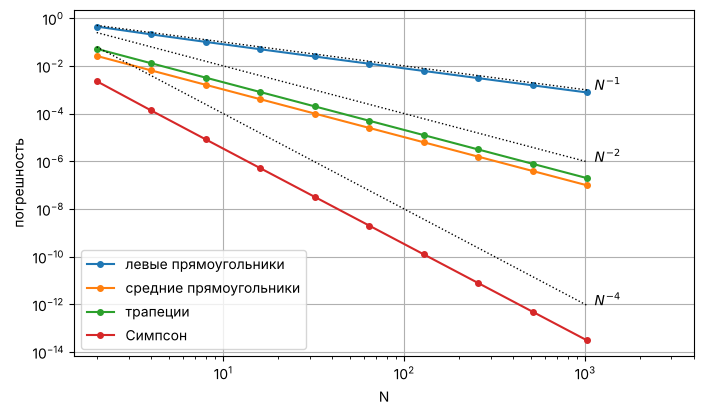

In [18]:
Ns_plot = 2 ** np.arange(1, 11)
for method, label in [(rect_left, 'левые прямоугольники'), (rect_mid, 'средние прямоугольники'),
                      (trapezoid, 'трапеции'), (simpson, 'Симпсон')]:
    errs = [abs(1 - method(np.sin, 0, np.pi / 2, N)) for N in Ns_plot]
    plt.loglog(Ns_plot, errs, 'o-', ms=4, label=label)
plt.loglog(Ns_plot, 1.0 / Ns_plot, 'k:', lw=1)
plt.loglog(Ns_plot, 1.0 / Ns_plot**2, 'k:', lw=1)
plt.loglog(Ns_plot, 1.0 / Ns_plot**4, 'k:', lw=1)
plt.text(Ns_plot[-1] * 1.1, 1.0 / Ns_plot[-1], '$N^{-1}$')
plt.text(Ns_plot[-1] * 1.1, 1.0 / Ns_plot[-1]**2, '$N^{-2}$')
plt.text(Ns_plot[-1] * 1.1, 1.0 / Ns_plot[-1]**4, '$N^{-4}$')
plt.xlim(1.5, 4000)
plt.xlabel('N')
plt.ylabel('погрешность')
plt.legend()
plt.show()

> **Для преподавателя.** В двойном логарифмическом масштабе степенная зависимость $h^p$ — прямая с наклоном $-p$. Пунктиром показаны наклоны 1, 2 и 4. У формулы Симпсона при N = 1024 погрешность уже около $3 \cdot 10^{-14}$, это близко к уровню ошибок округления: дальше увеличивать N бессмысленно.

### Когда порядок не достигается (просто запустите)

Порядок $p$ гарантирован только для достаточно гладких функций. У $\sqrt{x}$ производная в нуле бесконечна:

$$\int_0^1 \sqrt{x}\,dx = \frac{2}{3}.$$

In [19]:
order_table(simpson, np.sqrt, 0, 1, 2 / 3)

    N    погрешность   отношение
    4   1.014e-02
    8   3.587e-03       2.83
   16   1.268e-03       2.83
   32   4.485e-04       2.83
   64   1.586e-04       2.83
  128   5.606e-05       2.83


Отношение около $2.83 = 2^{1.5}$: порядок всего $1.5$ вместо $4$.

Бывает и наоборот. Для периодической функции на полном периоде формула трапеций сходится гораздо быстрее, чем $h^2$:

$$\int_0^{2\pi} e^{\cos x}\,dx.$$

In [20]:
from scipy.special import i0

def f_periodic(x):
    return np.exp(np.cos(x))

I_periodic = 2 * np.pi * i0(1.0)     # точное значение выражается через функцию Бесселя
for N in [2, 4, 8, 16]:
    print(N, abs(I_periodic - trapezoid(f_periodic, 0, 2 * np.pi, N)))

2 1.7405350514516442
4 0.03439691880919149
8 1.2516889320579594e-06
16 0.0


> **Для преподавателя.** Комментарии:
> - $\sqrt{x}$: порядок падает для всех формул, не только для Симпсона. Высокий порядок формулы бесполезен, если функция негладкая.
> - периодическая функция: при N = 16 погрешность уже на уровне округления. Главные члены погрешности формулы трапеций пропорциональны разностям производных на концах отрезка, а у периодической функции они все равны нулю. Формула трапеций для периодических функций — один из самых точных методов.
> 
> Для слабой группы этот подраздел можно пропустить.

## 5. Формула Рунге–Ромберга

Пока мы находили погрешность, зная точный ответ. Что делать, если он неизвестен?

Пусть формула имеет порядок $p$. Вычислим интеграл на двух сетках: с $N$ отрезками и с $rN$ отрезками (обычно $r = 2$). Тогда

$$\boxed{I = U_{rN} + R_{rN} + O(h^{p+1}), \qquad R_{rN} = \frac{U_{rN} - U_N}{r^p - 1}}$$

- $R_{rN}$ — **оценка погрешности** значения $U_{rN}$, вычисленная без знания точного ответа (апостериорная оценка).
- $U_{rN} + R_{rN}$ — **уточнённое значение**, более высокого порядка точности.

*Откуда формула.* $I = U_N + Ch^p + \dots$ и $I = U_{rN} + C\left(\dfrac{h}{r}\right)^p + \dots$ Вычитая, получаем $C\left(\dfrac{h}{r}\right)^p \approx \dfrac{U_{rN} - U_N}{r^p - 1}$.

In [21]:
U_N = trapezoid(np.sin, 0, np.pi / 2, 10)
U_2N = trapezoid(np.sin, 0, np.pi / 2, 20)
R_2N = (U_2N - U_N) / (2**2 - 1)

print(R_2N)
print(1 - U_2N)

0.0005143062980585977
0.0005140947514670202


> **Для преподавателя.** Ожидаемый результат: `0.00051431` и `0.00051409`. Оценка совпадает с настоящей погрешностью с точностью до четвёртого знака, хотя точный ответ при её вычислении не использовался.
> 
> Типичная ошибка: `2^2 - 1` вместо `2**2 - 1`.

Теперь уточнённое значение.

In [22]:
U_refined = U_2N + R_2N
print(1 - U_refined)
print(U_refined - simpson(np.sin, 0, np.pi / 2, 20))

-2.115465915775161e-07
2.220446049250313e-16


> **Для преподавателя.** Ожидаемый результат: погрешность $-2.1 \cdot 10^{-7}$ (была $5 \cdot 10^{-4}$), разность с формулой Симпсона порядка $10^{-16}$.
> 
> Это главный момент семинара: уточнение формулы трапеций по Рунге–Ромбергу даёт в точности формулу Симпсона. Проверка на бумаге: $U_{2N} + \dfrac{U_{2N} - U_N}{3} = \dfrac{4U_{2N} - U_N}{3}$. У узлов с чётными номерами (общих для двух сеток) вес $\dfrac{4h - 2h}{3} = \dfrac{2h}{3}$, у нечётных $\dfrac{4h}{3}$, у крайних $\dfrac{h}{3}$ (здесь $h$ — шаг мелкой сетки). Это веса Симпсона.

**Мини-задача.** Для $\displaystyle\int_1^2 \frac{dx}{x}$ вычислите формулу Симпсона при $N = 10$ и $N = 20$, оцените погрешность по формуле Рунге–Ромберга (чему равно $p$?) и сравните с настоящей погрешностью.

In [23]:
S_N = simpson(f_inv, 1, 2, 10)
S_2N = simpson(f_inv, 1, 2, 20)
R_S = (S_2N - S_N) / (2**4 - 1)
print(R_S, np.log(2) - S_2N)

-1.9040158761492638e-07 -1.9410517082540935e-07


> **Для преподавателя.** Ожидаемый результат: оценка $-1.90 \cdot 10^{-7}$, настоящая погрешность $-1.94 \cdot 10^{-7}$. Здесь $p = 4$, знаменатель $2^4 - 1 = 15$. Частая ошибка: оставить знаменатель 3 от формулы трапеций.

## 6. Методика Ричардсона

**Задача:** вычислить интеграл с заданной точностью $\varepsilon$, не зная точного ответа.

1. Вычисляем интеграл на последовательности сгущающихся сеток: $N,\ rN,\ r^2N,\ \dots$
2. На каждой новой сетке находим оценку погрешности $R_{rN}$ по формуле Рунге–Ромберга.
3. Останавливаемся, когда $|R_{rN}| < \varepsilon$.

Результат: значение $U$ на последней сетке и оценка его погрешности $R$ (а также уточнённое значение $U + R$).

In [24]:
def richardson(method, p, f, a, b, eps, N=4, r=2, max_steps=20):
    U_old = method(f, a, b, N)
    for k in range(max_steps):
        N = r * N
        U = method(f, a, b, N)
        R = (U - U_old) / (r**p - 1)
        print(N, U, R)
        if abs(R) < eps:
            break
        U_old = U
    return U, R

> **Для преподавателя.** Типичные ошибки: `U_old = U` стоит до проверки условия или вне цикла; `return` внутри цикла; перепутан порядок аргументов при вызове (сначала метод и его порядок p, затем функция и пределы).
> 
> Функция возвращает два значения. Студенты видели такое у `brentq(..., full_output=True)`: результат присваивается двум переменным через запятую.

In [25]:
U_trap, R_trap = richardson(trapezoid, 2, np.sin, 0, np.pi / 2, 1e-8)
print(1 - U_trap, R_trap)

8 0.9967851718861696 0.0032231236377980497
16 0.999196680485072 0.0008038361996341633
32 0.9997991943200187 0.00020083794498223137
64 0.999949800092101 5.020192402741911e-05
128 0.9999874501175261 1.2550008475035549e-05
256 0.9999968625352877 3.1374725872150102e-06
512 0.9999992156341911 7.84366301131989e-07
1024 0.9999998039085708 1.960914598845657e-07
2048 0.9999999509771441 4.902285777319548e-08
4096 0.999999987744286 1.2255713962202227e-08
8192 0.9999999969360714 3.063928481298698e-09
3.0639285553135664e-09 3.063928481298698e-09


> **Для преподавателя.** Ожидаемый результат: таблица от N = 8 до N = 8192; оценка R уменьшается в 4 раза на каждом шаге; в конце настоящая погрешность `3.06e-09` и оценка `3.06e-09` совпадают.

In [26]:
U_simp, R_simp = richardson(simpson, 4, np.sin, 0, np.pi / 2, 1e-8)
print(1 - U_simp, R_simp)

8 1.0000082955239677 -8.419296681738686e-06
16 1.0000005166847064 -5.185892840930961e-07
32 1.000000032265001 -3.229464703065806e-08
64 1.0000000020161286 -2.016591486390477e-09
-2.0161285974040766e-09 -2.016591486390477e-09


> **Для преподавателя.** Ожидаемый результат: остановка на N = 64 вместо 8192. Погрешность `-2.0e-09`, оценка `-2.0e-09`.
> 
> Вопрос аудитории: во сколько раз меньше вычислений функции? Примерно в 100 раз.

Теперь интеграл, точное значение которого неизвестно:

$$\int_0^1 e^{-x^2}\,dx.$$

In [27]:
def f_gauss(x):
    return np.exp(-x**2)

U_gauss, R_gauss = richardson(simpson, 4, f_gauss, 0, 1, 1e-10)
print(U_gauss + R_gauss)

8 0.7468261205274667 -1.9506175680398624e-06
16 0.7468242574357303 -1.2420611575543934e-07
32 0.746824140606985 -7.788583022971807e-09
64 0.7468241332996726 -4.871541614548391e-10
128 0.7468241328428813 -3.045275143165327e-11
0.7468241328124285


> **Для преподавателя.** Ожидаемый результат: остановка на N = 128, уточнённое значение `0.7468241328124...` (точное значение `0.746824132812427`).

### Можно ли доверять оценке? Эффективный порядок

Формула Рунге–Ромберга верна, только если погрешность действительно ведёт себя как $Ch^p$. Это можно проверить по трём сеткам, не зная точного ответа:

$$p_{\text{эфф}} = \log_r\frac{U_{rN} - U_N}{U_{r^2N} - U_{rN}}.$$

Если $p_{\text{эфф}}$ близок к теоретическому $p$, оценке можно доверять.

Пример: $\displaystyle\int_0^1\sqrt{x}\,dx$ по формуле Симпсона (просто запустите).

In [28]:
U_sqrt, R_sqrt = richardson(simpson, 4, np.sqrt, 0, 1, 1e-6)
print('оценка погрешности:   ', R_sqrt)
print('настоящая погрешность:', 2 / 3 - U_sqrt)

U_16, U_32, U_64 = simpson(np.sqrt, 0, 1, 16), simpson(np.sqrt, 0, 1, 32), simpson(np.sqrt, 0, 1, 64)
print('эффективный порядок:  ', np.log2((U_32 - U_16) / (U_64 - U_32)))

8 0.6630792800850236 0.000436867686163526
16 0.6653981886281528 0.00015459390287528112
32 0.6662181827461797 5.4666274535127475e-05
64 0.666508103078362 1.9328022145481682e-05
128 0.6666106059362655 6.833523860239054e-06
256 0.6666468462030954 2.4160177886608144e-06
512 0.6666596590744268 8.541914220912734e-07
оценка погрешности:    8.541914220912734e-07
настоящая погрешность: 7.007592239816063e-06
эффективный порядок:   1.4999570475476558


Оценка с $p = 4$ занижает погрешность в 8 раз: настоящий порядок равен $1.5$, и эффективный порядок это показывает.

> **Для преподавателя.** С правильным порядком `richardson(simpson, 1.5, np.sqrt, 0, 1, 1e-6)` оценка совпадает с настоящей погрешностью (задача 7 для быстрых). Для слабой группы этот подраздел можно пропустить.

## 7. Интегрирование в `scipy`

- `integrate.quad(f, a, b)` — интеграл от функции. Возвращает значение и оценку погрешности. Внутри используются квадратурные формулы Гаусса с автоматическим выбором узлов.
- `integrate.trapezoid(y, x)` и `integrate.simpson(y, x=x)` — формулы трапеций и Симпсона для табличных данных.

In [29]:
from scipy import integrate

print(integrate.quad(f_gauss, 0, 1))

(0.7468241328124271, 8.291413475940725e-15)


> **Для преподавателя.** Ожидаемый результат: `(0.7468241328124271, 8.29e-15)`: значение и оценка погрешности. Совпадает с нашим уточнённым значением.
> 
> Импортируем именно модуль (`from scipy import integrate`), а не функции: иначе `trapezoid` и `simpson` из scipy заменили бы функции, написанные студентами. Если кто-то напишет `from scipy.integrate import simpson`, его собственная функция `simpson` перестанет работать.

---
## 8. Задачи

### Основные

**Задача 1.** Вычислите $\displaystyle\int_0^1 e^x\,dx = e - 1$ формулами средних прямоугольников, трапеций и Симпсона при $N = 10$. Найдите погрешности (точное значение `np.e - 1`).

In [30]:
for method in [rect_mid, trapezoid, simpson]:
    print(np.e - 1 - method(np.exp, 0, 1, 10))

0.0007157419979173518
-0.0014316629302695283
-9.53465778552598e-07


**Задача 2.** Число $\pi$ можно вычислить как

$$\pi = \int_0^1 \frac{4}{1 + x^2}\,dx.$$

Вычислите его с точностью $10^{-6}$ методикой Ричардсона по формуле трапеций. Сколько отрезков понадобилось? Сравните результат и уточнённое значение с `np.pi`.

In [31]:
def f_pi(x):
    return 4 / (1 + x**2)

U_pi, R_pi = richardson(trapezoid, 2, f_pi, 0, 1, 1e-6)
print(np.pi - U_pi, np.pi - (U_pi + R_pi))

8 3.138988494491089 0.0026040079676178016
16 3.140941612041389 0.000651039183433344
32 3.1414298931749745 0.00016276037786185546
64 3.141551963485655 4.069010356018884e-05
128 3.1415824810637516 1.0172526032192764e-05
256 3.141590110458283 2.5431315104166665e-06
512 3.1415920178069157 6.357828776041666e-07
6.357828774561369e-07 0.0


**Задача 3.** Вычислите $\displaystyle\int_0^1 \sqrt{1 + x^3}\,dx$ с точностью $10^{-8}$ методикой Ричардсона по формуле Симпсона и сравните с результатом `integrate.quad`.

In [32]:
def f_root3(x):
    return np.sqrt(1 + x**3)

U_root3, R_root3 = richardson(simpson, 4, f_root3, 0, 1, 1e-8)
print(U_root3 + R_root3)
print(integrate.quad(f_root3, 0, 1))

8 1.111442701555604 5.297952780599265e-06
16 1.1114476426770474 3.2940809622239444e-07
32 1.1114479500644752 2.0492495182248643e-08
64 1.1114479692536765 1.2792800892687712e-09
1.1114479705329565
(1.1114479705325755, 1.2339551275581678e-14)


**Задача 4. Табличные данные.** Скорость автомобиля измеряли каждые 2 секунды в течение 20 секунд (таблица ниже). Найдите пройденный путь с помощью `integrate.trapezoid` и `integrate.simpson`.

In [33]:
t_table = np.arange(0, 21, 2.0)                                                         # время, с
v_table = np.array([0.0, 4.1, 7.8, 11.0, 13.6, 15.7, 17.3, 18.5, 19.4, 20.0, 20.4])     # скорость, м/с

In [34]:
print(integrate.trapezoid(v_table, t_table))
print(integrate.simpson(v_table, x=t_table))

275.2
275.8666666666667


**Задача 5. Возвращаемся к разминке.** Найдите $x$, при котором

$$\int_0^x e^{-t^2}\,dt = 0.5.$$

Указание: задайте функцию `F(x)`, которая вычисляет интеграл формулой Симпсона (например, при $N = 100$) и вычитает $0.5$, и найдите её корень с помощью `brentq` на отрезке $[0, 1]$.

In [35]:
def F(x):
    return simpson(f_gauss, 0, x, 100) - 0.5

print(brentq(F, 0.0, 1.0))

0.5510394275820162


*Ответы:* 1) погрешности $7.2 \cdot 10^{-4}$, $-1.4 \cdot 10^{-3}$, $-9.5 \cdot 10^{-7}$; 2) $N = 512$, погрешность $6.4 \cdot 10^{-7}$, у уточнённого значения на уровне ошибок округления; 3) $1.1114479705$, остановка на $N = 64$; 4) $275.2$ м и $275.87$ м; 5) $x \approx 0.5510394$.

> **Для преподавателя.** Задача 2: если студент возьмёт формулу Симпсона с $p = 4$, остановка произойдёт уже на N = 16, а настоящая погрешность окажется в несколько раз меньше оценки. Это особенность именно этого интеграла: у подынтегральной функции третья производная равна нулю на обоих концах отрезка, главный член погрешности Симпсона пропадает, и формула сходится с шестым порядком. Обсуждать стоит, только если кто-то заметит.
> 
> Задача 5: главная мысль та же, что и в прошлый раз, — численный метод можно использовать как обычную функцию внутри другого численного метода. Здесь `brentq` на каждой итерации вызывает нашу формулу Симпсона. Проверка: $x = \operatorname{erf}^{-1}(1/\sqrt{\pi})$, `scipy.special.erfinv(1 / np.sqrt(np.pi))` даёт `0.5510394276`.

### Для тех, кто справился быстрее

**Задача 6. Период маятника.** Период колебаний математического маятника с амплитудой $\theta_0$ (не обязательно малой) равен

$$\frac{T}{T_0} = \frac{2}{\pi}\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1 - k^2\sin^2\varphi}}, \qquad k = \sin\frac{\theta_0}{2},$$

где $T_0 = 2\pi\sqrt{l/g}$ — период малых колебаний. Вычислите $T/T_0$ для амплитуд $10°$, $45°$, $90°$ и $150°$ (перевод в радианы: `np.radians`). При какой из этих амплитуд формула малых колебаний ещё даёт ошибку меньше $1\%$?

In [36]:
for theta_deg in [10, 45, 90, 150]:
    k = np.sin(np.radians(theta_deg) / 2)
    def f_pend(phi):
        return 1 / np.sqrt(1 - k**2 * np.sin(phi)**2)
    print(theta_deg, 2 / np.pi * simpson(f_pend, 0, np.pi / 2, 100))

10 1.0019071881432164
45 1.0399733431968041
90 1.1803405990160964
150 1.7622037295037563


*Ответ:* $1.0019$, $1.0400$, $1.1803$, $1.7622$. Ошибка меньше $1\%$ только при $10°$.

**Задача 7. Эффективный порядок.** Для $\displaystyle\int_0^1\sqrt{x}\,dx$ и формулы трапеций:
1. Найдите эффективный порядок по сеткам $N = 16, 32, 64$.
2. Запустите `richardson` с точностью $10^{-6}$ сначала с теоретическим порядком $p = 2$, затем с найденным эффективным порядком. В каком случае оценка $R$ ближе к настоящей погрешности $2/3 - U$?

In [37]:
T_16, T_32, T_64 = trapezoid(np.sqrt, 0, 1, 16), trapezoid(np.sqrt, 0, 1, 32), trapezoid(np.sqrt, 0, 1, 64)
p_eff = np.log2((T_32 - T_16) / (T_64 - T_32))
print(p_eff)

for p in [2, p_eff]:
    U_s, R_s = richardson(trapezoid, p, np.sqrt, 0, 1, 1e-6)
    print('p =', p, ' оценка:', R_s, ' настоящая погрешность:', 2 / 3 - U_s)

1.4741562971342912
8 0.6581302216244543 0.004949058460569256
16 0.6635811968772283 0.0018169917509246458
32 0.6655589362789418 0.0006592464672378432
64 0.6662708113785067 0.0002372916998549801
128 0.666525657296826 8.49486394397525e-05
256 0.6666165489765281 3.0297226567369922e-05
512 0.666648881549952 1.0777524474647748e-05
1024 0.6666603622189842 3.826889677371881e-06
2048 0.6666644335929708 1.3571246622046118e-06
4096 0.6666658761271795 4.808447362503188e-07
p = 2  оценка: 4.808447362503188e-07  настоящая погрешность: 7.905394870943994e-07
8 0.6581302216244543 0.008349500365222164
16 0.6635811968772283 0.0030654261631425507
32 0.6655589362789418 0.001112207233523094
64 0.6662708113785067 0.00040033213395815364
128 0.666525657296826 0.00014331588557265823
256 0.6666165489765281 5.111410711854409e-05
512 0.666648881549952 1.818263923415276e-05
1024 0.6666603622189842 6.456302145844154e-06
2048 0.6666644335929708 2.289589616491629e-06
4096 0.6666658761271795 8.112276977377625e-07
p = 1

*Ответ:* эффективный порядок около $1.47$ (при увеличении $N$ стремится к $1.5$). С $p = 2$ оценка занижает погрешность примерно в $1.6$ раза, с эффективным порядком оценка и настоящая погрешность почти совпадают.

---
## Итоги

| Формула | Порядок $p$ | Погрешность при удвоении $N$ |
|---|---|---|
| Левые прямоугольники | 1 | уменьшается в 2 раза |
| Средние прямоугольники | 2 | в 4 раза |
| Трапеции | 2 | в 4 раза |
| Симпсон | 4 | в 16 раз |

- Формула Рунге–Ромберга по двум сеткам даёт оценку погрешности $R_{rN} = \dfrac{U_{rN} - U_N}{r^p - 1}$ и уточнённое значение $U_{rN} + R_{rN}$.
- Методика Ричардсона: сгущаем сетку, пока оценка погрешности не станет меньше заданной точности.
- Порядок достигается только для гладких функций; эффективный порядок позволяет это проверить.

> **Для преподавателя.** В итогах проговорите общую практическую мысль: результат численного расчёта без оценки погрешности мало чего стоит. Формула Рунге–Ромберга даёт такую оценку почти бесплатно и применима не только к интегралам, а к любому методу с известным порядком точности (в том числе к решению дифференциальных уравнений, которые будут дальше в курсе).

---
## 9. Домашнее задание

### Основная часть

**ДЗ 1. Период маятника.** Используя формулу из задачи 6, постройте график зависимости $T/T_0$ от амплитуды $\theta_0$ в диапазоне от $1°$ до $170°$. На том же графике нарисуйте приближение $1 + \theta_0^2/16$ ($\theta_0$ в радианах). С помощью `brentq` найдите амплитуду, при которой период отличается от $T_0$ ровно на $1\%$.

**ДЗ 2. Цена точности.** Для $\displaystyle\int_0^1 e^x\,dx$ определите методикой Ричардсона, сколько отрезков нужно формулам средних прямоугольников, трапеций и Симпсона, чтобы достичь точности $10^{-8}$. Сделайте вывод.

**ДЗ 3. Таблица и сплайн.** Функция $\sin x$ задана таблицей в 7 равноотстоящих точках на $[0, \pi]$. Вычислите интеграл тремя способами: `integrate.trapezoid`, `integrate.simpson` и через кубический сплайн (`CubicSpline(x, y).integrate(0, np.pi)`). Сравните с точным значением $2$.

### Задачи повышенной сложности (по желанию)

**ДЗ 4. Метод Ромберга.** Уточнение по Рунге–Ромбергу можно применять повторно. Пусть $T_{k,0}$ — формула трапеций на сетке из $2^k$ отрезков, а

$$T_{k,m} = T_{k,m-1} + \frac{T_{k,m-1} - T_{k-1,m-1}}{4^m - 1}.$$

Постройте таблицу $T_{k,m}$ для $\displaystyle\int_0^{\pi/2}\sin x\,dx$ при $k = 0, \dots, 5$ и напечатайте погрешности. Какой столбец соответствует формуле Симпсона? Какая точность достигается при 33 вычислениях функции?

**ДЗ 5. Формулы Гаусса.** Узлы и веса формулы Гаусса на $[-1, 1]$ даёт функция `np.polynomial.legendre.leggauss(n)`. Отрезок $[a, b]$ отображается на $[-1, 1]$ заменой $x = \dfrac{a + b}{2} + \dfrac{b - a}{2}t$. Вычислите $\displaystyle\int_0^1 e^x\,dx$ формулами Гаусса с $n = 2, 3, 5$ узлами и сравните погрешность с формулой Симпсона при том же числе вычислений функции.

**ДЗ 6. Периодические функции.** Исследуйте сходимость формул трапеций и Симпсона для $\displaystyle\int_0^{2\pi} e^{\cos x}\,dx$ (точное значение `2 * np.pi * scipy.special.i0(1.0)`). Какая из формул точнее? Попробуйте объяснить результат.

---
## Решения домашнего задания (только в версии преподавателя)

**ДЗ 1.**

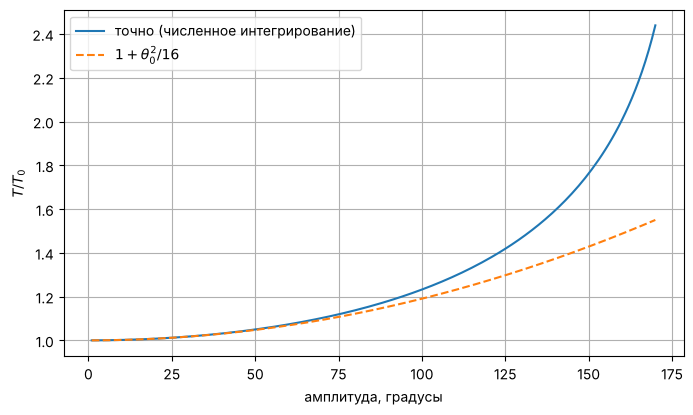

1% при амплитуде 22.813849261956253 градусов


In [38]:
def period_ratio(theta0):
    k = np.sin(theta0 / 2)
    def f_pend(phi):
        return 1 / np.sqrt(1 - k**2 * np.sin(phi)**2)
    return 2 / np.pi * simpson(f_pend, 0, np.pi / 2, 200)

theta_deg = np.linspace(1, 170, 170)
theta_rad = np.radians(theta_deg)
ratios = [period_ratio(th) for th in theta_rad]

plt.plot(theta_deg, ratios, label='точно (численное интегрирование)')
plt.plot(theta_deg, 1 + theta_rad**2 / 16, '--', label=r'$1 + \theta_0^2/16$')
plt.xlabel('амплитуда, градусы')
plt.ylabel('$T / T_0$')
plt.legend()
plt.show()

theta_1pct = brentq(lambda th: period_ratio(th) - 1.01, 0.01, 1.0)
print('1% при амплитуде', np.degrees(theta_1pct), 'градусов')

Период отличается от $T_0$ на $1\%$ при амплитуде около $22.8°$. Приближение $1 + \theta_0^2/16$ хорошо работает примерно до $60°$.

**ДЗ 2.**

In [39]:
import io, contextlib

for method, p in [(rect_mid, 2), (trapezoid, 2), (simpson, 4)]:
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):                 # прячем таблицу, оставляем только итог
        U_e, R_e = richardson(method, p, np.exp, 0, 1, 1e-8)
    N_last = int(buf.getvalue().strip().split('\n')[-1].split()[0])
    print(f'{method.__name__:10s}  N = {N_last:6d}   погрешность {np.e - 1 - U_e: .2e}')

rect_mid    N =   4096   погрешность  4.27e-09
trapezoid   N =   4096   погрешность -8.53e-09
simpson     N =     32   погрешность -9.10e-09


Формулам второго порядка нужны тысячи отрезков, формуле Симпсона — десятки. Средние прямоугольники вдвое точнее трапеций, но порядок тот же. (Студентам достаточно посмотреть на последнюю строку таблицы, которую печатает `richardson`.)

**ДЗ 3.**

In [40]:
from scipy.interpolate import CubicSpline

x_tab = np.linspace(0, np.pi, 7)
y_tab = np.sin(x_tab)
print('трапеции:', 2 - integrate.trapezoid(y_tab, x_tab))
print('Симпсон: ', 2 - integrate.simpson(y_tab, x=x_tab))
print('сплайн:  ', 2 - CubicSpline(x_tab, y_tab).integrate(0, np.pi))

трапеции: 0.04590276668629345
Симпсон:  -0.0008631896735362687
сплайн:   -0.0003556995828311038


Интегрирование через сплайн — это сплайн-квадратура из лекций. Для гладкой функции сплайн и формула Симпсона дают сравнимую точность, намного выше, чем у трапеций.

**ДЗ 4.**

In [41]:
K = 6
T = np.zeros((K, K))
for k in range(K):
    T[k, 0] = trapezoid(np.sin, 0, np.pi / 2, 2**k)
    for m in range(1, k + 1):
        T[k, m] = T[k, m - 1] + (T[k, m - 1] - T[k - 1, m - 1]) / (4**m - 1)

np.set_printoptions(precision=2, linewidth=120)
print(np.abs(1 - T) * (T != 0))

[[2.15e-01 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00]
 [5.19e-02 2.28e-03 0.00e+00 0.00e+00 0.00e+00 0.00e+00]
 [1.29e-02 1.35e-04 8.43e-06 0.00e+00 0.00e+00 0.00e+00]
 [3.21e-03 8.30e-06 1.24e-07 8.14e-09 0.00e+00 0.00e+00]
 [8.03e-04 5.17e-07 1.90e-09 2.98e-11 1.98e-12 0.00e+00]
 [2.01e-04 3.23e-08 2.96e-11 1.15e-13 2.00e-15 1.11e-16]]


Столбец $m = 1$ — формула Симпсона, $m = 2$ — формула Буля и т. д. При $k = 5$ (33 вычисления функции) диагональный элемент имеет погрешность на уровне ошибок округления, тогда как формула трапеций на той же сетке даёт всего $2 \cdot 10^{-4}$.

**ДЗ 5.**

In [42]:
def gauss(f, a, b, n):
    t, w = np.polynomial.legendre.leggauss(n)
    x = 0.5 * (a + b) + 0.5 * (b - a) * t
    return 0.5 * (b - a) * np.sum(w * f(x))

for n in [2, 3, 5]:
    err_g = abs(np.e - 1 - gauss(np.exp, 0, 1, n))
    N_s = n - 1 if (n - 1) % 2 == 0 else n      # число отрезков Симпсона с примерно тем же числом узлов
    err_s = abs(np.e - 1 - simpson(np.exp, 0, 1, N_s))
    print(f'n = {n}: Гаусс {err_g:.2e};  Симпсон (N = {N_s}, узлов {N_s + 1}) {err_s:.2e}')

n = 2: Гаусс 3.85e-04;  Симпсон (N = 2, узлов 3) 5.79e-04
n = 3: Гаусс 8.24e-07;  Симпсон (N = 2, узлов 3) 5.79e-04
n = 5: Гаусс 6.54e-13;  Симпсон (N = 4, узлов 5) 3.70e-05


Формула Гаусса с $n$ узлами точна для многочленов степени $2n - 1$, поэтому при том же числе вычислений функции она на много порядков точнее формулы Симпсона (для гладких функций).

**ДЗ 6.**

In [43]:
print('    N    трапеции     Симпсон')
for N in [2, 4, 8, 16, 32]:
    print(f'{N:5d}   {abs(I_periodic - trapezoid(f_periodic, 0, 2 * np.pi, N)):.2e}   '
          f'{abs(I_periodic - simpson(f_periodic, 0, 2 * np.pi, N)):.2e}')

    N    трапеции     Симпсон
    2   1.74e+00   7.21e-01
    4   3.44e-02   5.34e-01
    8   1.25e-06   1.15e-02
   16   0.00e+00   4.17e-07
   32   0.00e+00   1.78e-15


Для периодической функции на полном периоде формула трапеций точнее формулы Симпсона. Погрешность формулы трапеций раскладывается по разностям нечётных производных на концах отрезка (формула Эйлера–Маклорена), а у периодической функции все они равны нулю. Формула Симпсона — это комбинация трапеций на двух сетках, $\dfrac{4T_N - T_{N/2}}{3}$, и её точность ограничена более грубой сеткой.